In [1]:
import numpy as np
import pandas as pd #Permite mostrar tablas como si fuesen de excel
import matplotlib.pyplot as plt

In [2]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=12)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

<h1>Aplicación 1: Reducción de colores de una imagen con K-means</h1>

<h1>Problema</h1>
<p>Una imagen guarda cada píxel con 3 valores: rojo, verde y azul, cada uno de 0 a 255. Eso da hasta 16.7 millones de colores posibles y ocupa 24 bits por píxel.</p>
<p>La pregunta es: ¿se puede representar la imagen con solo k colores sin que se pierda mucho?</p>
<ul>
  <li>Cada píxel es un punto en 3 dimensiones (R, G, B).</li>
  <li>K-means agrupa los píxeles de colores parecidos.</li>
  <li>El centroide de cada grupo es el color que representa a ese grupo.</li>
  <li>Al final, cada píxel se reemplaza por el color de su centroide: la imagen queda con solo k colores.</li>
</ul>
<p>Esto se usa para comprimir imágenes (por ejemplo en GIF o PNG con paleta) y para sacar paletas de colores.</p>

<h1>Dataset</h1>
<p>Se usa la imagen de ejemplo china.jpg que viene incluida en Scikit-Learn, así que no hay que descargar nada.</p>

In [3]:
from sklearn.datasets import load_sample_image

In [4]:
imagen = load_sample_image('china.jpg') #Para usar una imagen propia: imagen = plt.imread('mi_foto.jpg')

In [5]:
imagen.shape #(alto, ancho, canales)

(427, 640, 3)

In [6]:
alto, ancho, _ = imagen.shape #El "_" ignora el número de canales (siempre es 3)

print(f'Píxeles totales = {alto * ancho}')

Píxeles totales = 273280


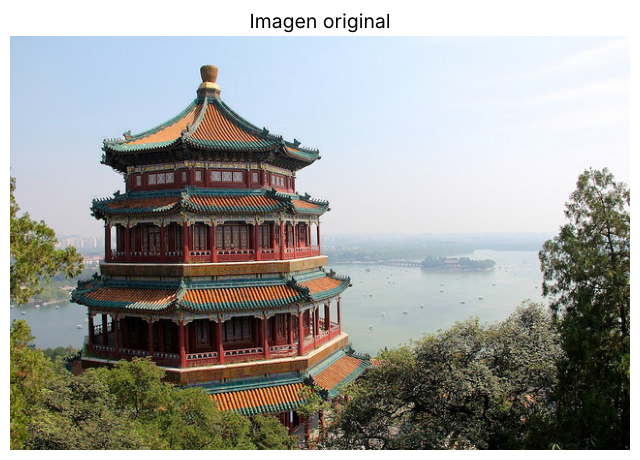

In [7]:
plt.figure(figsize=(8, 6))
plt.imshow(imagen)
plt.title('Imagen original')
plt.axis('off')
plt.show()

<h1>Preparación de los datos</h1>
<p>La imagen es una matriz de alto × ancho × 3. Se convierte en una tabla con una fila por píxel y 3 columnas, y se divide entre 255 para que cada valor quede entre 0 y 1:</p>

$$x_i = (R_i, G_i, B_i) \qquad 0 \le R_i, G_i, B_i \le 1$$

In [8]:
X = imagen.reshape(alto * ancho, 3) / 255 #Una fila por píxel y una columna por canal (R, G, B)
X.shape

(273280, 3)

In [9]:
colores_originales = len(set([tuple(p) for p in imagen.reshape(alto * ancho, 3)])) #Un set no guarda repetidos, así que su tamaño es el número de colores distintos

print(f'Colores distintos en la imagen original = {colores_originales}')

Colores distintos en la imagen original = 96615


<p>Para que el proceso sea rápido, K-means se entrena con una muestra aleatoria de 10,000 píxeles y después se usa para asignar todos los píxeles a su color más cercano.</p>

In [10]:
rng = np.random.default_rng(seed=42)

indices = rng.permutation(len(X))[:10000] #Revuelve las posiciones y toma las primeras 10,000 (sin repetir)
X_muestra = X[indices]
X_muestra.shape

(10000, 3)

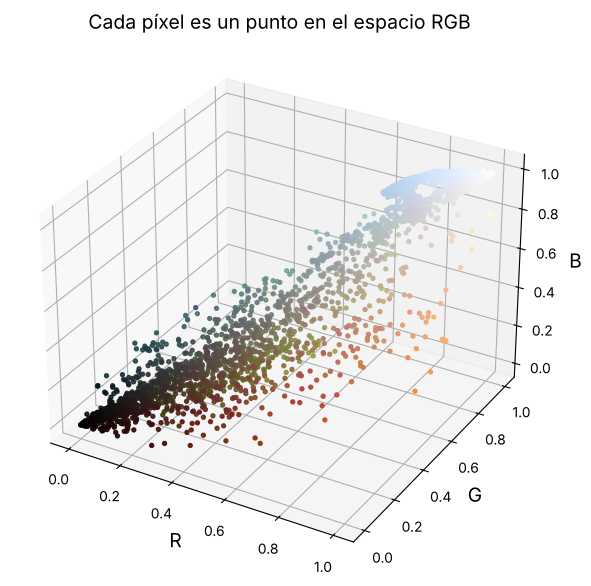

In [11]:
puntos = X_muestra[:3000] #Solo 3,000 para que la gráfica no se sature

fig = plt.figure(figsize=(8, 7))
ax = plt.axes(projection='3d') #Gráfica en 3 dimensiones
ax.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2], c=puntos, s=8) #Cada punto se pinta de su propio color
ax.set_xlabel('R')
ax.set_ylabel('G')
ax.set_zlabel('B')
plt.title('Cada píxel es un punto en el espacio RGB')
plt.show()

<h1>Número óptimo de clusters</h1>
<h2>Método del codo</h2>
<p>Para cada k se calcula la inercia: la suma de las distancias al cuadrado de cada punto al centroide de su grupo. Siempre baja al aumentar k; se busca el "codo", donde deja de bajar mucho.</p>

$$J = \sum_{i=1}^{m} \left\| x_i - \mu_{c_i} \right\|^2$$

<h2>Coeficiente de silueta</h2>
<p>Compara la distancia promedio de un punto a los de su grupo (a) contra la distancia promedio al grupo vecino más cercano (b). Va de −1 a 1; más alto es mejor.</p>

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

<p>La silueta se calcula sobre 3,000 píxeles porque compara todos los puntos contra todos.</p>

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [13]:
ks = range(2, 17)
inercias = []
siluetas = []

for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=4, random_state=42).fit(X_muestra)
    inercias.append(kmeans.inertia_) #inertia_ es J
    siluetas.append(silhouette_score(X_muestra, kmeans.labels_, sample_size=3000, random_state=42))

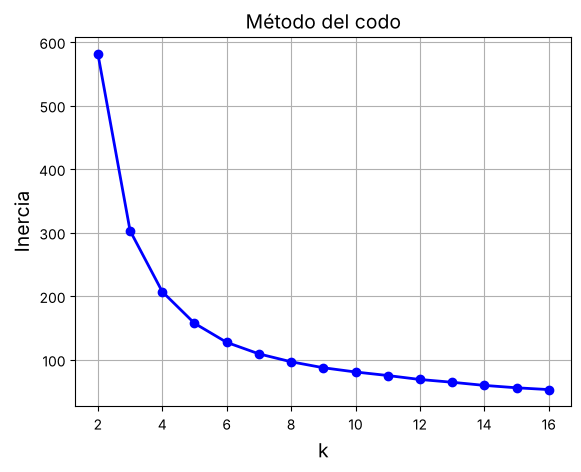

In [14]:
plt.plot(ks, inercias, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Inercia')
plt.title('Método del codo')
plt.grid(True)
plt.show()

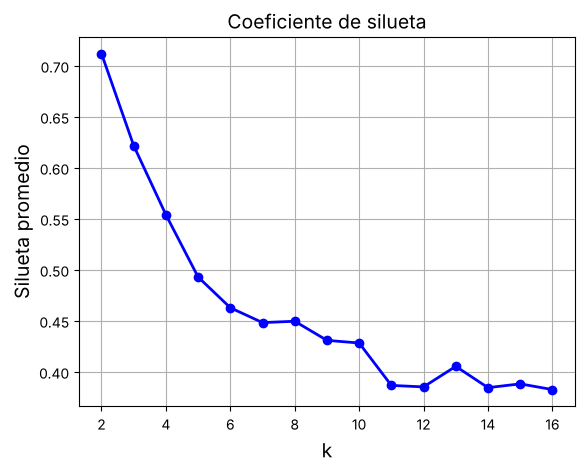

In [15]:
plt.plot(ks, siluetas, 'b-o', linewidth=2)
plt.xlabel('k')
plt.ylabel('Silueta promedio')
plt.title('Coeficiente de silueta')
plt.grid(True)
plt.show()

<p>Observación: el codo aparece alrededor de k = 4 a 6. La silueta es máxima en k = 2, porque la separación más clara de esta foto es "cielo claro" contra "todo lo demás", pero con 2 colores la imagen se pierde.</p>
<p>En una foto los colores cambian de forma gradual, así que no hay grupos muy separados. Por eso aquí k no se elige solo con las métricas, sino con un compromiso entre calidad y tamaño: más colores = imagen más fiel pero más pesada.</p>

<h1>K-means con Scikit-Learn</h1>
<p>Se entrena K-means con la muestra y con <code>predict</code> se asigna cada píxel de la imagen a su centroide más cercano. Luego cada píxel toma el color de su centroide.</p>

In [16]:
def reducir_colores(k):
    kmeans = KMeans(n_clusters=k, n_init=4, random_state=42).fit(X_muestra)
    etiquetas = kmeans.predict(X) #A qué grupo pertenece cada píxel de la imagen completa
    X_nueva = kmeans.cluster_centers_[etiquetas] #Cada píxel se reemplaza por el color de su centroide
    return kmeans, etiquetas, X_nueva.reshape(alto, ancho, 3) #Se regresa a la forma de imagen

In [17]:
valores_k = [2, 4, 8, 16, 32]
resultados = {}

for k in valores_k:
    resultados[k] = reducir_colores(k)

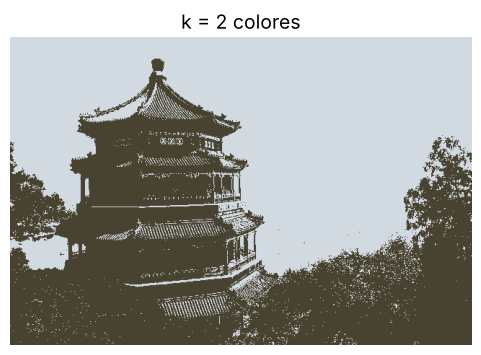

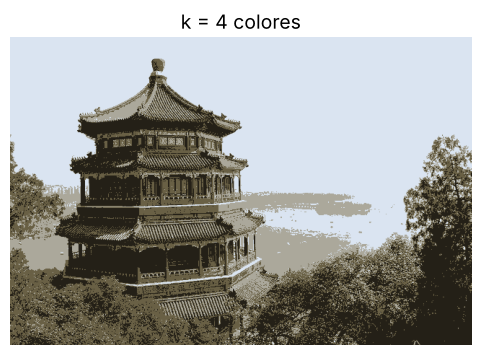

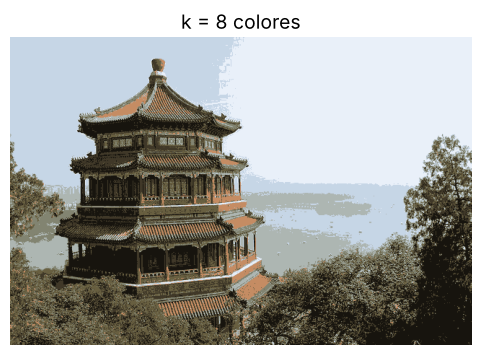

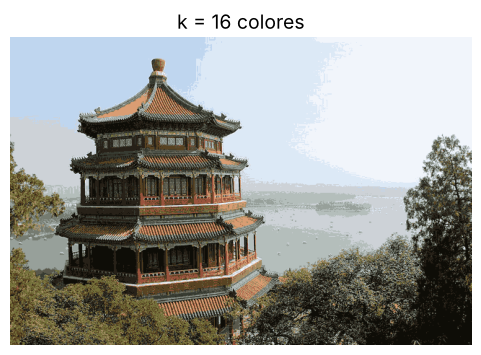

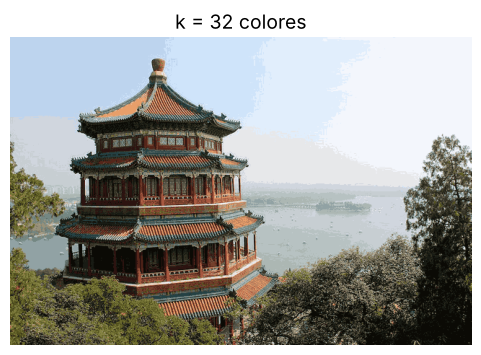

In [18]:
for k in valores_k:
    plt.figure(figsize=(6, 4))
    plt.imshow(resultados[k][2])
    plt.title(f'k = {k} colores')
    plt.axis('off')
    plt.show()

<h2>Paleta encontrada (k = 8)</h2>
<p>Cada centroide es un color. Se muestran los 8 colores en una franja y una tabla con su valor RGB (0 a 255) y el porcentaje de píxeles que lo usan.</p>

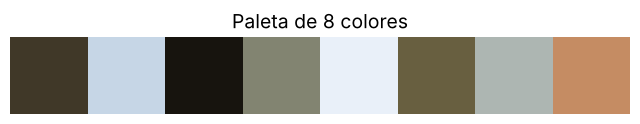

In [19]:
kmeans, etiquetas, _ = resultados[8]

centros = kmeans.cluster_centers_

plt.figure(figsize=(8, 2))
plt.imshow(centros.reshape(1, 8, 3)) #La paleta se dibuja como una imagen de 1 x 8 píxeles
plt.title('Paleta de 8 colores')
plt.axis('off')
plt.show()

In [20]:
porcentaje = [100 * (etiquetas == g).sum() / len(etiquetas) for g in range(8)] #(etiquetas == g).sum() cuenta los píxeles del grupo g

paleta = pd.DataFrame(centros * 255, columns=['R', 'G', 'B']).round(0)
paleta['% de píxeles'] = porcentaje
paleta.round(1)

,R,G,B,% de píxeles
0,64.0,57.0,41.0,13.1
1,199.0,214.0,231.0,18.2
2,24.0,21.0,14.0,15.4
3,130.0,132.0,113.0,7.2
4,234.0,241.0,249.0,23.8
5,104.0,95.0,65.0,11.8
6,174.0,182.0,179.0,7.7
7,198.0,141.0,100.0,2.9


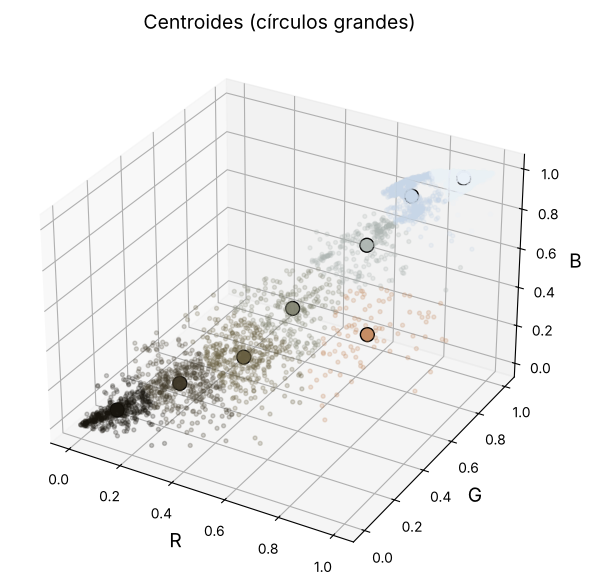

In [21]:
asignados = kmeans.predict(puntos)

fig = plt.figure(figsize=(8, 7))
ax = plt.axes(projection='3d')
ax.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2], c=centros[asignados], s=8, alpha=0.5) #Cada punto con el color de su centroide
ax.scatter(centros[:, 0], centros[:, 1], centros[:, 2], c=centros, s=100, edgecolors='black') #Centroides
ax.set_xlabel('R')
ax.set_ylabel('G')
ax.set_zlabel('B')
plt.title('Centroides (círculos grandes)')
plt.show()

<h1>Compresión y error</h1>
<p>Con k colores, cada píxel solo necesita guardar el número de su color, que ocupa:</p>

$$\text{bits por píxel} = \lceil \log_2 k \rceil$$

<p>más la paleta (k colores × 24 bits). La imagen original usa 24 bits por píxel. El error es la diferencia promedio por canal entre la original y la reconstruida (escala de 0 a 255).</p>

In [22]:
m = alto * ancho
tamano_original = m * 24 / 8 / 1024 #bits -> bytes -> KB

filas = []
for k in valores_k:
    bits = int(np.ceil(np.log(k) / np.log(2))) #log2(k) = log(k) / log(2)
    tamano = (m * bits + k * 24) / 8 / 1024
    error = np.abs(resultados[k][2] - imagen / 255).mean() * 255
    filas.append([k, bits, tamano, 100 * tamano / tamano_original, error])

print(f'Tamaño original = {tamano_original:.0f} KB')
pd.DataFrame(filas, columns=['k', 'Bits por píxel', 'Tamaño (KB)', '% del original', 'Error (0-255)']).round(1)

Tamaño original = 801 KB


,k,Bits por píxel,Tamaño (KB),% del original,Error (0-255)
0,2,1,33.4,4.2,29.0
1,4,2,66.7,8.3,17.4
2,8,3,100.1,12.5,11.2
3,16,4,133.5,16.7,8.0
4,32,5,166.9,20.8,6.0


<h1>Conclusiones</h1>
<ul>
  <li>K-means trata cada píxel como un punto (R, G, B) y resume miles de colores en k colores: los centroides.</li>
  <li>Con 16 colores la imagen se ve casi igual que la original y ocupa alrededor de 1/6 del espacio (4 bits por píxel en lugar de 24).</li>
  <li>Con pocos colores (2 o 4) se pierde detalle, pero se conservan las formas.</li>
  <li>Con k = 8 el verde de los árboles se vuelve gris oliva, pero el naranja del techo sobrevive aunque lo usan muy pocos píxeles: es un color muy distinto al resto y dejarlo sin centroide propio aumentaría mucho la inercia.</li>
</ul>
<p>Limitaciones: el resultado depende de k y de la inicialización; K-means solo ve el color de cada píxel, no su posición en la imagen; y las zonas pequeñas con un color único pueden desaparecer porque pesan poco en la inercia.</p>